# CASSPAR

CASSPAR estimates the spatial autoregressive model $y_t = \rho W y_t + X_t \beta + \varepsilon_t$ when the spatial weight matrix $W$ is unknown. $W$ is estimated by DirectLiNGAM (Step 1), and $\rho$ and $\beta$ by 2SLS (Step 2).

## Import and settings
In this example, we need to import `numpy` and `matplotlib` in addition to `lingam` and `casspar`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lingam
import casspar
from casspar import CASSPAR

print([np.__version__, lingam.__version__, casspar.__version__])

np.set_printoptions(precision=3, suppress=True)

['2.4.1', '1.12.1', '0.1.0']


## Test data
We create test data on a square grid. The spatial effects spread outward from a center location (default: the middle of the grid) along the 4-neighbors, using `make_radial_W`. $W$ is row-standardized and divided by its largest singular value, so any grid size and any center can be used.

X and $\varepsilon$ are uniform with mean zero. CASSPAR assumes centered (or standardized) data.

In [2]:
def make_radial_W(n, center=None):
    """W on an n x n grid where effects spread outward from `center` = (row, col).
    W[j, i] != 0 means an edge i -> j, drawn between 4-neighbors from the closer
    to the farther location. `center=None` is the middle of the grid."""
    center = center if center is not None else (n // 2, n // 2)
    coords = [(r, c) for r in range(n) for c in range(n)]
    dist = [np.hypot(r - center[0], c - center[1]) for r, c in coords]
    W = np.zeros((n * n, n * n))
    for i, (r, c) in enumerate(coords):
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            rr, cc = r + dr, c + dc
            if 0 <= rr < n and 0 <= cc < n:
                j = rr * n + cc
                if dist[i] < dist[j]:
                    W[j, i] = 1.0
    W = W / np.maximum(W.sum(axis=1, keepdims=True), 1)
    return W / np.linalg.svd(W, compute_uv=False)[0]


n = 5                   # grid is n x n
center = (2, 2)         # None for the middle of the grid
W = make_radial_W(n, center)

rho, beta = 0.7, np.array([1.0, -2.0, 0.5])
T, P, K = 1000, n * n, 3

rng = np.random.default_rng(0)
X = rng.uniform(-1, 1, size=(T, P, K))
e = rng.uniform(-1, 1, size=(T, P))
Y = (X @ beta + e) @ np.linalg.inv(np.eye(P) - rho * W).T

print(Y.shape, X.shape)

(1000, 25) (1000, 25, 3)


## Visualization
`plot_W_heatmap` shows $W$ as a heatmap, and `plot_causal_arrows` draws it as arrows on the grid (an arrow from location $i$ to $j$ means $W_{ji} \neq 0$; thicker means larger).

In [3]:
def plot_W_heatmap(W, ax, title=None):
    """Heatmap of W. Row j, column i is the effect of location i on location j."""
    lim = np.abs(W).max()
    im = ax.imshow(W, cmap="coolwarm", vmin=-lim, vmax=lim)
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xlabel("from (i)")
    ax.set_ylabel("to (j)")
    ax.set_title(title)


def plot_causal_arrows(W, ax, grid_shape, threshold=0.1, title=None):
    """Spatial causal structure on a grid. An arrow i -> j is drawn for W[j, i] != 0.
    Weights smaller than `threshold` * max|W| are omitted. Line width grows with |W|."""
    n_rows, n_cols = grid_shape
    max_w = np.abs(W).max()
    offset = 0.15
    for i in range(W.shape[0]):
        r_i, c_i = divmod(i, n_cols)
        for j in range(W.shape[0]):
            w = W[j, i]
            if i == j or abs(w) < threshold * max_w:
                continue
            r_j, c_j = divmod(j, n_cols)
            dx, dy = c_j - c_i, r_j - r_i
            length = np.hypot(dx, dy)
            ux, uy = dx / length, dy / length
            ax.arrow(c_i + offset * ux, r_i + offset * uy,
                     dx - 2 * offset * ux, dy - 2 * offset * uy,
                     length_includes_head=True, head_width=0.15, head_length=0.2,
                     linewidth=4.0 * (abs(w) / max_w) ** 3, alpha=0.9)
    ax.set_xticks(range(n_cols))
    ax.set_yticks(range(n_rows))
    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, color="gray", linewidth=0.5, alpha=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title)


def show_W(W, grid_shape, title):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    plot_W_heatmap(W, axes[0], f"{title}: heatmap")
    plot_causal_arrows(W, axes[1], grid_shape, title=f"{title}: spatial causal structure")
    fig.tight_layout()
    plt.show()

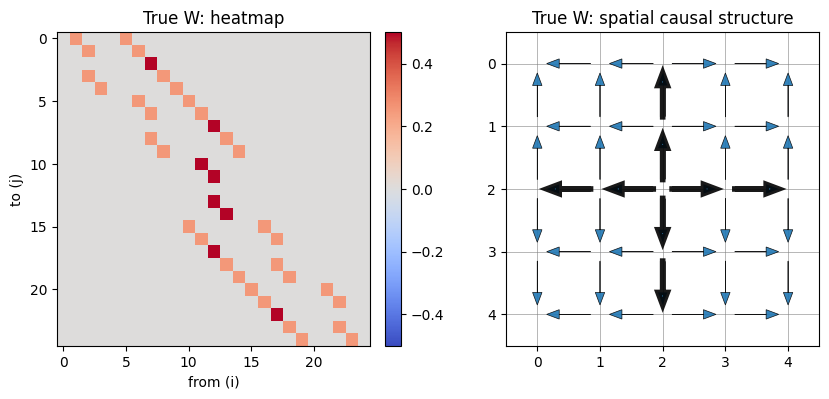

In [4]:
grid_shape = (n, n)
show_W(W, grid_shape, 'True W')

## Causal discovery
To run CASSPAR, we create a `CASSPAR` object and call the `fit` method with Y `(n_samples, n_locations)` and X `(n_samples, n_locations, n_covariates)`.

In [5]:
model = CASSPAR(random_state=0)
model.fit(Y, X)

Using the `causal_order_` properties, we can see the causal ordering of the locations as a result of Step 1.

In [6]:
model.causal_order_

[np.int64(12),
 np.int64(17),
 np.int64(7),
 np.int64(6),
 np.int64(2),
 np.int64(1),
 np.int64(13),
 np.int64(14),
 np.int64(5),
 np.int64(8),
 np.int64(3),
 np.int64(0),
 np.int64(9),
 np.int64(4),
 np.int64(22),
 np.int64(24),
 np.int64(19),
 np.int64(18),
 np.int64(11),
 np.int64(16),
 np.int64(21),
 np.int64(10),
 np.int64(15),
 np.int64(20),
 np.int64(23)]

`adjacency_matrix_` is $W$ estimated by DirectLiNGAM, and `spatial_weight_matrix_` is $W$ after the normalization, which is used in Step 2.

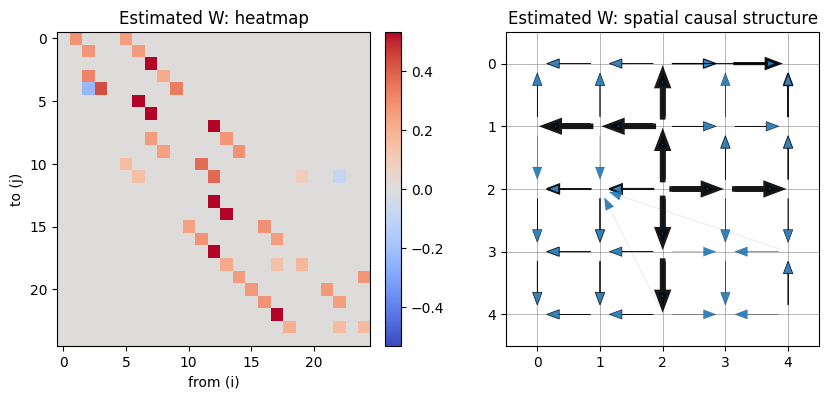

In [7]:
show_W(model.spatial_weight_matrix_, grid_shape, 'Estimated W')

## Estimated parameters
$\rho$, $\beta$ and the intercept estimated in Step 2.

In [8]:
print(f'rho: {model.rho_:.3f} (true: {rho})')
print('beta:', model.coef_, '(true:', beta, ')')
print(f'intercept: {model.intercept_:.3f}')

rho: 0.595 (true: 0.7)
beta: [ 0.988 -1.99   0.505] (true: [ 1.  -2.   0.5] )
intercept: -0.006


## Prediction
`predict` returns $\hat{y}_t = (I - \hat{\rho} \hat{W})^{-1} X_t \hat{\beta}$ for new X.

In [9]:
X_new = rng.uniform(-1, 1, size=(200, P, K))
Y_new = (X_new @ beta + rng.uniform(-1, 1, size=(200, P))) @ np.linalg.inv(np.eye(P) - rho * W).T

Y_pred = model.predict(X_new)
print(f'MAE: {np.mean(np.abs(Y_new - Y_pred)):.3f}')

MAE: 0.537


## Bootstrap estimation of W
With `n_bootstrap`, $W$ in Step 1 is the element-wise median of the estimates on bootstrap samples. It is disabled by default. `n_jobs` runs the bootstrap in parallel.

rho: 0.593
beta: [ 0.984 -1.992  0.506]
(10, 25, 25)


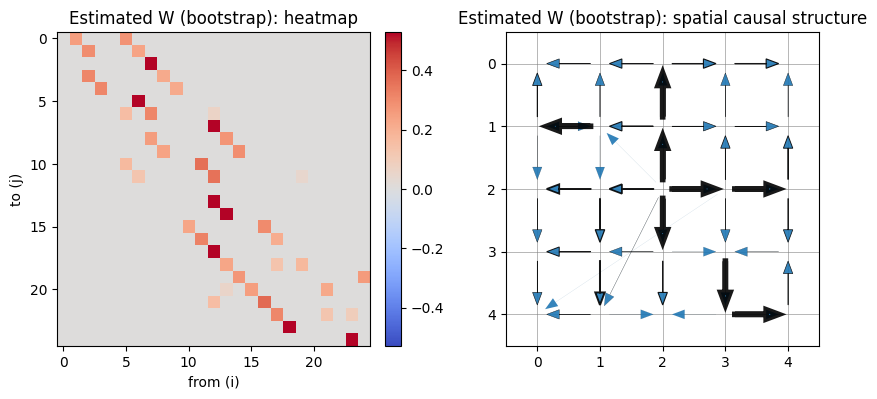

In [10]:
model_bs = CASSPAR(n_bootstrap=10, random_state=0)
model_bs.fit(Y, X)

print(f'rho: {model_bs.rho_:.3f}')
print('beta:', model_bs.coef_)
print(model_bs.bootstrap_adjacency_matrices_.shape)

show_W(model_bs.spatial_weight_matrix_, grid_shape, 'Estimated W (bootstrap)')